In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('food_delivery_raw.csv')
raw = df.copy()

Saving food_delivery_raw.csv to food_delivery_raw.csv


In [ ]:
print(df.shape)

(45584, 20)


In [ ]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

In [ ]:
df.isna().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


# step 1:load and inspect
-Raw Date:45584 rows, 20columns
-Dates and times are stored as text
-Missing values found in age, ratings, weather, traffic, and others


In [ ]:
df=df.drop(columns=['Restaurant_latitude',
'Restaurant_longitude',
'Delivery_location_latitude',
'Delivery_location_longitude'	])
print(df.shape)

(45584, 16)


In [ ]:
df=df.rename(columns={'ID':'Order_id',

                   'multiple_deliveries':'Multiple_deliveries',
                     'Time_taken (min)':'Time_taken_min' })
print(df.columns)

Index(['Order_id', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'Multiple_deliveries', 'Festival', 'City', 'Time_taken_min'],
      dtype='object')


In [ ]:
df.columns=df.columns.str.lower()
print(df.columns)

Index(['order_id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'order_date', 'time_orderd',
       'time_order_picked', 'weather_conditions', 'road_traffic_density',
       'vehicle_condition', 'type_of_order', 'type_of_vehicle',
       'multiple_deliveries', 'festival', 'city', 'time_taken_min'],
      dtype='object')


# Step 2: Initial Data Cleaning
- Dropped four unused geographical columns: `Restaurant_latitude`, `Restaurant_longitude`, `Delivery_location_latitude`, and `Delivery_location_longitude`(zeros and negative values, not needed for my questions)
- Renamed `ID` to `order_id`.
- Renamed `Time_taken (min)` to `time_taken_min`.
- Converted all column names to lowercase snake_case for consistency and readability.
- Now 45,584 rows and 16 columns

In [ ]:
for c in['weather_conditions','road_traffic_density','multiple_deliveries','type_of_order', 'type_of_vehicle','festival', 'city']:
 print(c)
 print(df[c].value_counts(dropna=False))
 print()

weather_conditions
weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
NaN            616
Name: count, dtype: int64

road_traffic_density
road_traffic_density
Low       15476
Jam       14139
Medium    10945
High       4423
NaN         601
Name: count, dtype: int64

multiple_deliveries
multiple_deliveries
1.0    28151
0.0    14094
2.0     1985
NaN      993
3.0      361
Name: count, dtype: int64

type_of_order
type_of_order
Snack     11530
Meal      11456
Drinks    11321
Buffet    11277
Name: count, dtype: int64

type_of_vehicle
type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

festival
festival
No     44460
Yes      896
NaN      228
Name: count, dtype: int64

city
city
Metropolitian    34087
Urban            10133
NaN               1200
Semi-Urban         164
Name: count, dtype: int64



In [ ]:
for c in['weather_conditions','road_traffic_density','type_of_order', 'type_of_vehicle','festival', 'city']:
  df[c]=df[c].str.strip()

In [ ]:
df['city']=df['city'].replace({'Metropolitian': 'Metropolitan'})
df['city'].value_counts(dropna=False)

,count
city,
Metropolitan,34087
Urban,10133
NaN,1200
Semi-Urban,164


## Step 3: Text cleaning
- Removed extra spaces from 6 text columns
- Fixed city typo "Metropolitian" to "Metropolitan" (34,087 rows)
- Missing values in weather, traffic, festival and city still to handle

In [ ]:
df[['order_date', 'time_orderd',
       'time_order_picked']].head(10)
df.loc[~df['time_order_picked'].str.contains(':'),'time_order_picked'].value_counts().head()




,count
time_order_picked,
0.833333333,452
1,440
0.916666667,430
0.75,422
0.875,416


In [40]:
df['order_date']= pd.to_datetime(df['order_date'],dayfirst=True)
print(df['order_date'].min(),df['order_date'].max())


2022-02-11 00:00:00 2022-04-06 00:00:00


In [ ]:
df['order_date'].head(10)

,order_date
0,2022-02-12
1,2022-02-13
2,2022-03-04
3,2022-02-13
4,2022-02-14
5,2022-04-02
6,2022-03-01
7,2022-03-16
8,2022-03-20
9,2022-02-15


In [ ]:
print(df['order_date'].head(10))
print(df['order_date'].dtype)

0   2022-02-12
1   2022-02-13
2   2022-03-04
3   2022-02-13
4   2022-02-14
5   2022-04-02
6   2022-03-01
7   2022-03-16
8   2022-03-20
9   2022-02-15
Name: order_date, dtype: datetime64[ns]
datetime64[ns]


In [ ]:
print("Earliest date:", df['order_date'].min())
print("Latest date:", df['order_date'].max())

Earliest date: 2022-02-11 00:00:00
Latest date: 2022-04-06 00:00:00


In [ ]:
def to_hour(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if ':' in s:
        return int(s.split(':')[0]) % 24
    return int(float(s) * 24 + 1e-6) % 24

df['order_hour'] = df['time_orderd'].apply(to_hour).fillna(df['time_order_picked'].apply(to_hour)).astype(int)
df = df.drop(columns=['time_orderd', 'time_order_picked'])

In [ ]:
print(df['order_hour'].isna().sum())
print(sorted(df['order_hour'].unique()))
df[['order_date', 'order_hour']].dtypes

0
[np.int64(0), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


,0
order_date,datetime64[ns]
order_hour,int64


## Step 4: Dates and times
- order_date was text (day-month-year); converted to datetime with dayfirst=True
- Time columns had 3 mixed formats (21:55, decimals like 0.83, and 24:05:00)
- Created order_hour (0-23); 1,731 missing order times filled using the pickup hour (assumption)
- Dropped the original time columns

In [ ]:
print('age under 18:', (df['delivery_person_age'] < 18).sum())
print('rating above 5:', (df['delivery_person_ratings'] > 5).sum())
df[['delivery_person_age', 'delivery_person_ratings']].describe()


age under 18: 38
rating above 5: 53


,delivery_person_age,delivery_person_ratings
count,43730.000000,43676.000000
mean,29.566911,4.633774
std,5.815064,0.334744
min,15.000000,1.000000
25%,25.000000,4.500000
50%,30.000000,4.700000
75%,35.000000,4.900000
max,50.000000,6.000000


In [ ]:
df.loc[df['delivery_person_age'] < 18, 'delivery_person_age'] = np.nan
df.loc[df['delivery_person_ratings'] > 5, 'delivery_person_ratings'] = np.nan

print(df['delivery_person_age'].isna().sum(), df['delivery_person_ratings'].isna().sum())

1892 1961


## Step 5: Impossible values
- 38 partners with age under 18 (minimum was 15): set to missing
- 53 ratings above 5 (maximum was 6): set to missing
- Will fill these in Step 6 with the median

In [ ]:
df.isna().sum()

,0
order_id,0
delivery_person_id,0
delivery_person_age,1892
delivery_person_ratings,1961
order_date,0
weather_conditions,616
road_traffic_density,601
vehicle_condition,0
type_of_order,0
type_of_vehicle,0


In [ ]:
before = len(df)
df = df.dropna(subset=['road_traffic_density', 'weather_conditions'])
print('rows dropped:', before - len(df))
print('rows left:', len(df))

rows dropped: 616
rows left: 44968


In [ ]:
df['delivery_person_age'] = df['delivery_person_age'].fillna(df['delivery_person_age'].median())
df['delivery_person_ratings'] = df['delivery_person_ratings'].fillna(df['delivery_person_ratings'].median())

print(df['delivery_person_age'].median(), df['delivery_person_ratings'].median())

30.0 4.7


In [ ]:
print(df.isna().sum().sum())
df.isna().sum()

2384


,0
order_id,0
delivery_person_id,0
delivery_person_age,0
delivery_person_ratings,0
order_date,0
weather_conditions,0
road_traffic_density,0
vehicle_condition,0
type_of_order,0
type_of_vehicle,0


In [ ]:
df['type_of_vehicle'].value_counts()

,count
type_of_vehicle,
motorcycle,26277
scooter,15073
electric_scooter,3618


## Step 6: Missing values
- Dropped 616 rows with missing traffic/weather (1.4%); needed for Q1 and Q2
- Filled age with median (30) and rating with median (4.7)
- Filled multiple_deliveries with most common value (1)
- Filled festival and city with 'Unknown'
- Side effect: all 68 bicycle orders were in the dropped rows, so only 3 vehicle types remain
- Now 44,968 rows and 0 missing values

In [ ]:
df['multiple_deliveries'] = df['multiple_deliveries'].fillna(df['multiple_deliveries'].mode()[0]).astype(int)
df['festival'] = df['festival'].fillna('Unknown')
df['city'] = df['city'].fillna('Unknown')

In [ ]:
df = df.copy()

In [ ]:
df.columns

Index(['order_id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'order_date', 'weather_conditions',
       'road_traffic_density', 'vehicle_condition', 'type_of_order',
       'type_of_vehicle', 'multiple_deliveries', 'festival', 'city',
       'time_taken_min', 'order_hour'],
      dtype='object')

In [ ]:
print(raw['multiple_deliveries'].isna().sum())
print(raw['Festival'].isna().sum(), raw['City'].isna().sum())

993
228 1200


In [ ]:
   df.to_csv('food_delivery_clean.csv', index=False)
   files.download('food_delivery_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cleaning Log

**Raw data:** 45,584 rows, 20 columns
**Clean data:** 44,968 rows, 15 columns, 0 missing values, 0 duplicates

| # | Column | Problem | Fix | Rows affected |
|---|--------|---------|-----|---------------|
| 1 | 4 coordinate columns | Zeros and negative values (not valid), not needed for my questions | Dropped the columns | 4 columns |
| 2 | Column names | Typo `Time_Orderd`, spaces and brackets in `Time_taken (min)` | Renamed to simple lowercase names | All |
| 3 | city | Typo 'Metropolitian' | Corrected to 'Metropolitan' | 34,087 |
| 4 | order_date | Stored as text | Converted to date (day first) | All |
| 5 | Time columns | 3 mixed formats; 1,731 missing order times | Created `order_hour` (0 to 23); filled missing from pickup hour | All / 1,731 |
| 6 | age | 1,854 missing, 38 under 18 | Invalid set to missing; filled with median (30) | 1,892 |
| 7 | ratings | 1,908 missing, 53 above 5 | Invalid set to missing; filled with median (4.7) | 1,961 |
| 8 | traffic, weather | 601 and 616 missing | Dropped the rows (needed for Q1 and Q2) | 616 |
| 9 | multiple_deliveries | 993 missing | Filled with most common value (1) | 993 |
| 10 | festival, city | 228 and 1,200 missing | Filled with 'Unknown' | 228 / 1,200 |

### Assumptions and side effects
- Missing order times were filled using the pickup hour (pickup happens a few minutes after ordering).
- The 68 bicycle orders were all among the 616 dropped rows (incomplete records), so vehicle comparison covers 3 types.
- Coordinates were dropped, not fixed, because no question needs them.

In [ ]:
import os
import matplotlib.pyplot as plt
os.makedirs('images',exist_ok=True)

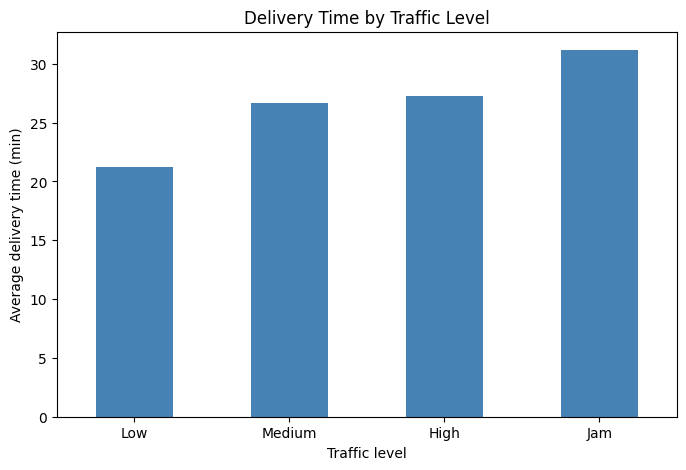

In [ ]:
order=["Low","Medium","High","Jam"]
ax=df.groupby('road_traffic_density')['time_taken_min'].mean().reindex(order).plot(kind='bar',rot=0,color='steelblue',figsize=(8,5),title='Delivery Time by Traffic Level')
ax.set_ylabel('Average delivery time (min)')
ax.set_xlabel('Traffic level')
plt.savefig('images/01_traffic.png', dpi=150, bbox_inches='tight')

Delivery time rises from 5 min in Low traffic to 30 min in Jam, about 25 minutes longer. So the company should add more partners during peak hours and show the customer real longer estimated time and company can offer ₹20–₹50 off the next order,Free delivery on the next order,acomplimentary dessert or beverage or A refund of the delivery fee. depending on the delay  during traffic jams.

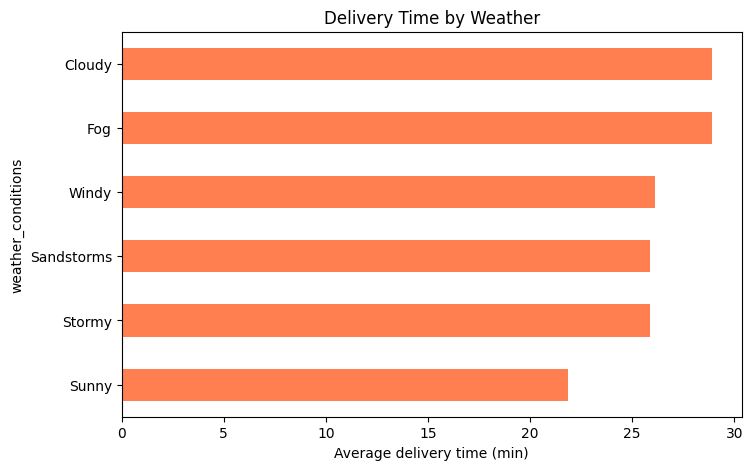

In [ ]:
ax = df.groupby('weather_conditions')['time_taken_min'].mean().sort_values().plot(
    kind='barh', color='coral', figsize=(8, 5), title='Delivery Time by Weather')
ax.set_xlabel('Average delivery time (min)')
plt.savefig('images/02_weather.png', dpi=150, bbox_inches='tight')

cloudy and fog weather have the longest delivery times about( 30 min), while sunny is fastest(23 min). So the company should warn customer about delays in fog and cloudy weather condtions and also company can offer a bonus to delivery partners as weather bonus  in bad weather.

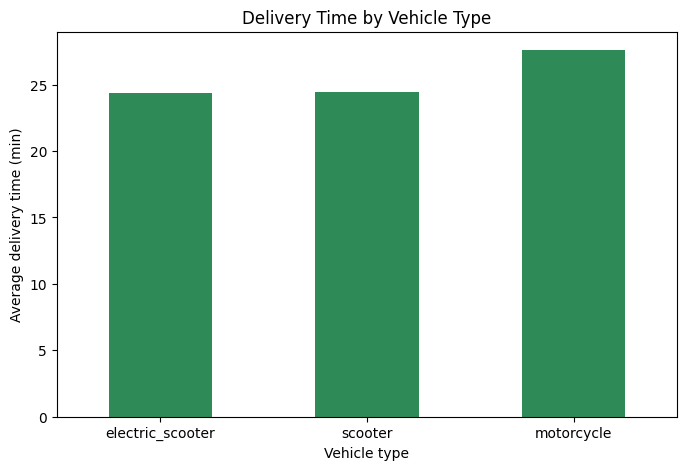

In [ ]:
ax = df.groupby('type_of_vehicle')['time_taken_min'].mean().sort_values().plot(
    kind='bar', rot=0, color='seagreen', figsize=(8, 5), title='Delivery Time by Vehicle Type')
ax.set_ylabel('Average delivery time (min)')
ax.set_xlabel('Vehicle type')
plt.savefig('images/03_vehicle.png', dpi=150, bbox_inches='tight')

motorcycle is the slowest vehicle (27 min) and electric scooter is the fastest (22 min). So the company should assign motorcycles to shorter distances, or review why they are slower.

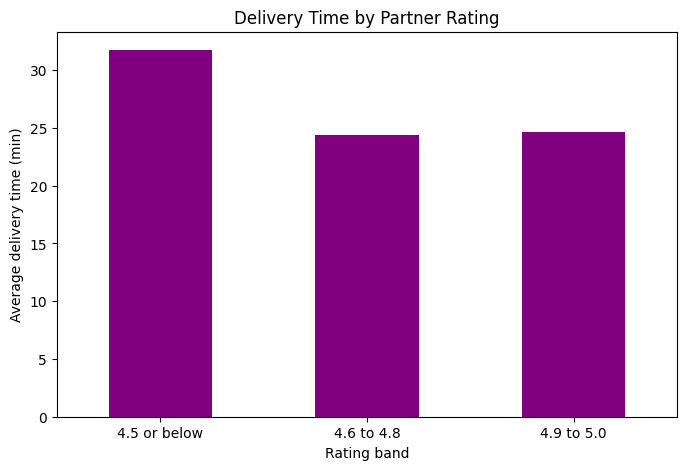

In [ ]:
bands = pd.cut(df['delivery_person_ratings'], bins=[0, 4.5, 4.8, 5.0],
               labels=['4.5 or below', '4.6 to 4.8', '4.9 to 5.0'])

ax = df.groupby(bands, observed=True)['time_taken_min'].mean().plot(
    kind='bar', rot=0, color='purple', figsize=(8, 5), title='Delivery Time by Partner Rating')
ax.set_ylabel('Average delivery time (min)')
ax.set_xlabel('Rating band')
plt.savefig('images/04_rating.png', dpi=150, bbox_inches='tight')

Partners rated 4.5 or below take 30 min, about 5 to 7 minutes longer than higher-rated partners (24 min). So the company could train or support low-rated partners, or give them shorter routes

In [ ]:
df.groupby('type_of_order')['time_taken_min'].mean().round(1)

,time_taken_min
type_of_order,
Buffet,26.3
Drinks,26.2
Meal,26.4
Snack,26.3


In [ ]:
print(df.groupby('road_traffic_density')['time_taken_min'].mean().round(1))
print(df.groupby('weather_conditions')['time_taken_min'].mean().round(1).sort_values())
print(df.groupby('time_taken_min')['time_taken_min'].mean().round(1).sort_values())


road_traffic_density
High      27.2
Jam       31.2
Low       21.3
Medium    26.7
Name: time_taken_min, dtype: float64
weather_conditions
Sunny         21.9
Stormy        25.9
Sandstorms    25.9
Windy         26.1
Cloudy        28.9
Fog           28.9
Name: time_taken_min, dtype: float64
time_taken_min
10    10.0
11    11.0
12    12.0
13    13.0
14    14.0
15    15.0
16    16.0
17    17.0
18    18.0
19    19.0
20    20.0
21    21.0
22    22.0
23    23.0
24    24.0
25    25.0
26    26.0
27    27.0
28    28.0
29    29.0
30    30.0
31    31.0
32    32.0
33    33.0
34    34.0
35    35.0
36    36.0
37    37.0
38    38.0
39    39.0
40    40.0
41    41.0
42    42.0
43    43.0
44    44.0
45    45.0
46    46.0
47    47.0
48    48.0
49    49.0
50    50.0
51    51.0
52    52.0
53    53.0
54    54.0
Name: time_taken_min, dtype: float64


In [ ]:
df.columns

Index(['order_id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'order_date', 'weather_conditions',
       'road_traffic_density', 'vehicle_condition', 'type_of_order',
       'type_of_vehicle', 'multiple_deliveries', 'festival', 'city',
       'time_taken_min', 'order_hour'],
      dtype='object')